# `Материалы кафедры ММП факультета ВМК МГУ. Введение в Эффективные Системы Глубокого Обучения.`

# `Лекция 7. Методы эффективного инференса: от эффективного батчирования до современных фреймворков`

## `Материалы составил: Табаченков Андрей (@taband58)`

### `Москва, Осенний семестр 2026`

Источник (1 раздел):

[Лекция Романа Горба, Осенний семестр 2025 года](https://github.com/mmp-effml-team/mmp_effml_fall_2025/blob/main/Seminars/03-inerence-challenges/inference_lecture.pdf)

# Задача инференса

Широкое разнообразие по задачам:
- Генеративные
  - Question-Answering
  - Диалоговые системы
  - Суммаризация и т. д.
- Дискриминативные
  - Классификация
  - Регрессия
  - Распознавание именованных сущностей (NER)

моделям:
- Модели на основе декодировщика (GPT-like)
- Encoder-Decoder модели (UL2, T5)
- Разные по размеру
  - Compute vs memory bound
  - OOM/not OOM
- Размера батча
- Supervised Fine-Tune VS Parameter-Efficient Fine-Tuning

этапам работы:
- Обработка контекста (prefill)
- Декодирование (генерация нового текста)

архитектурам и ограничениям GPU:
- Типы ядер: CUDA vs Tensor
- Memory transfer and compute
- VRAM vs 10x faster Streaming Multiprocessor (SM)
- VRAM vs SM with much less memory capacity


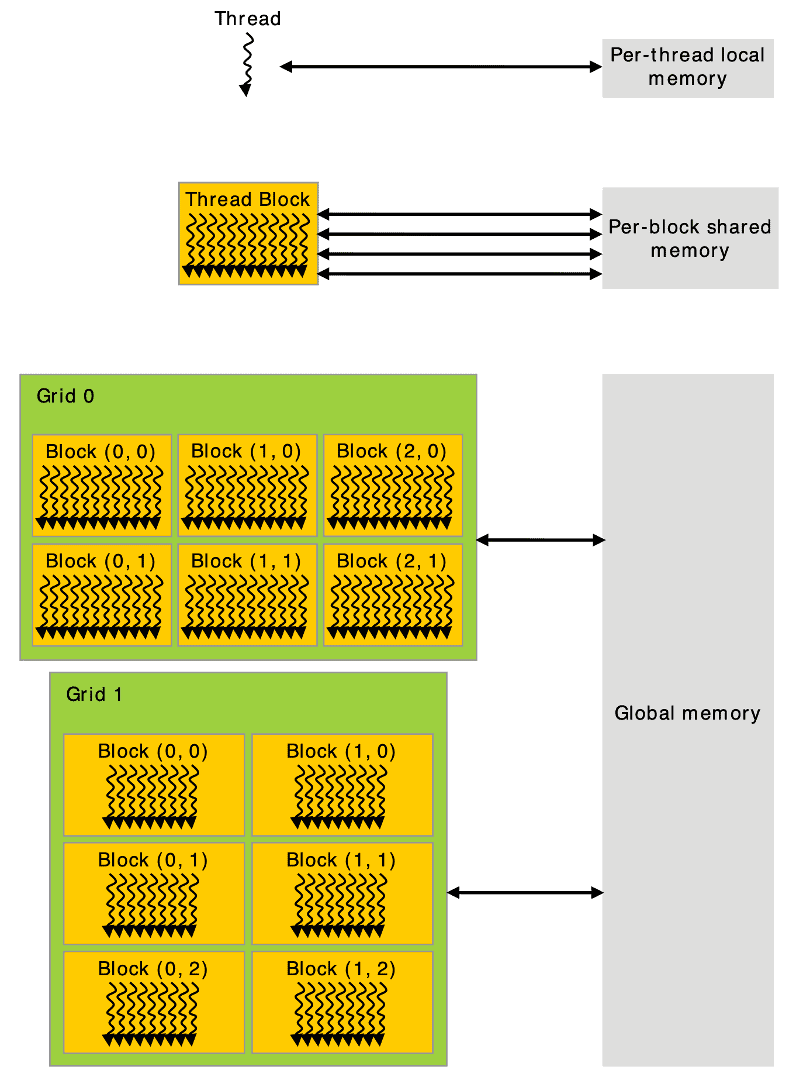

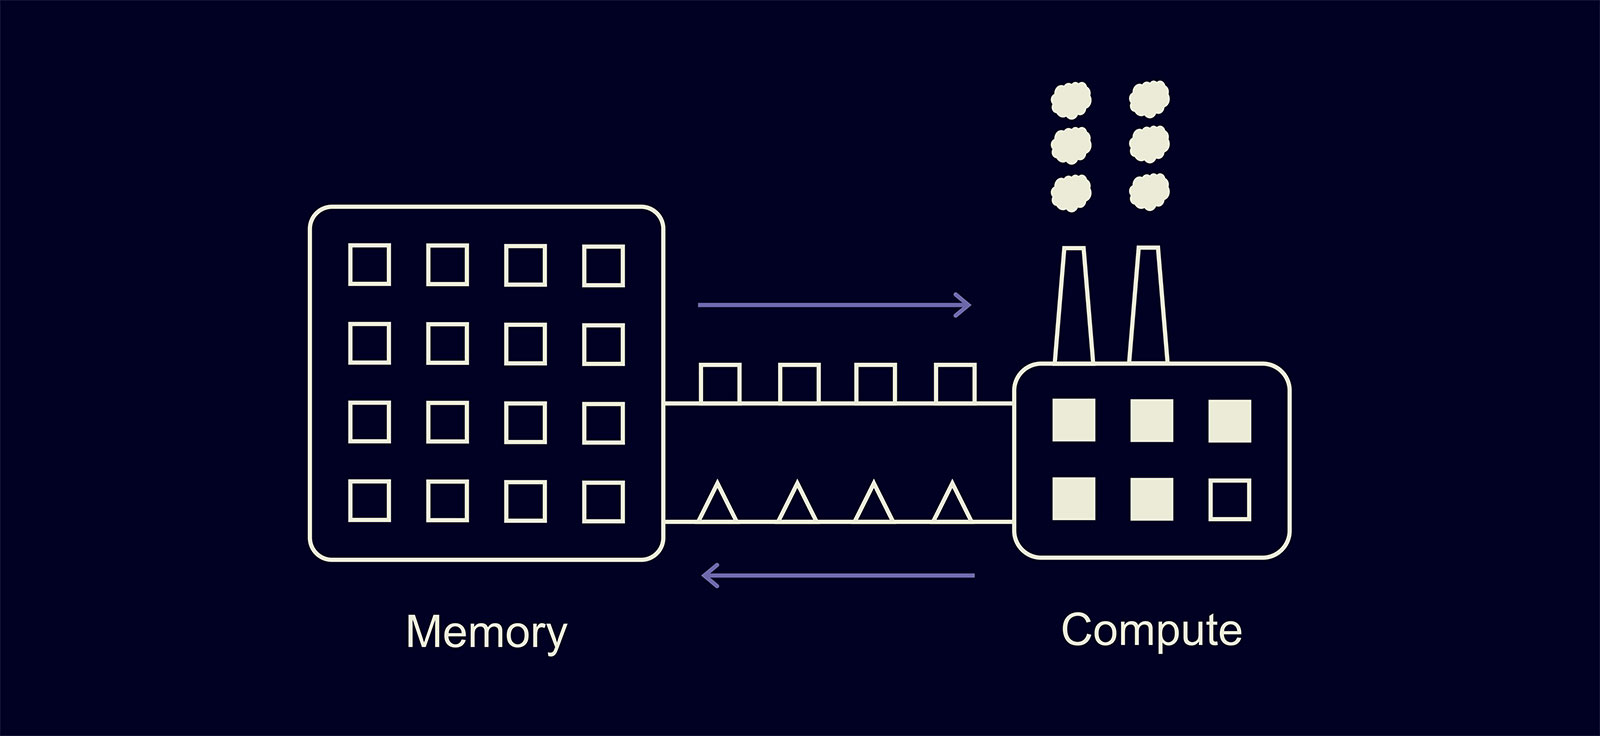

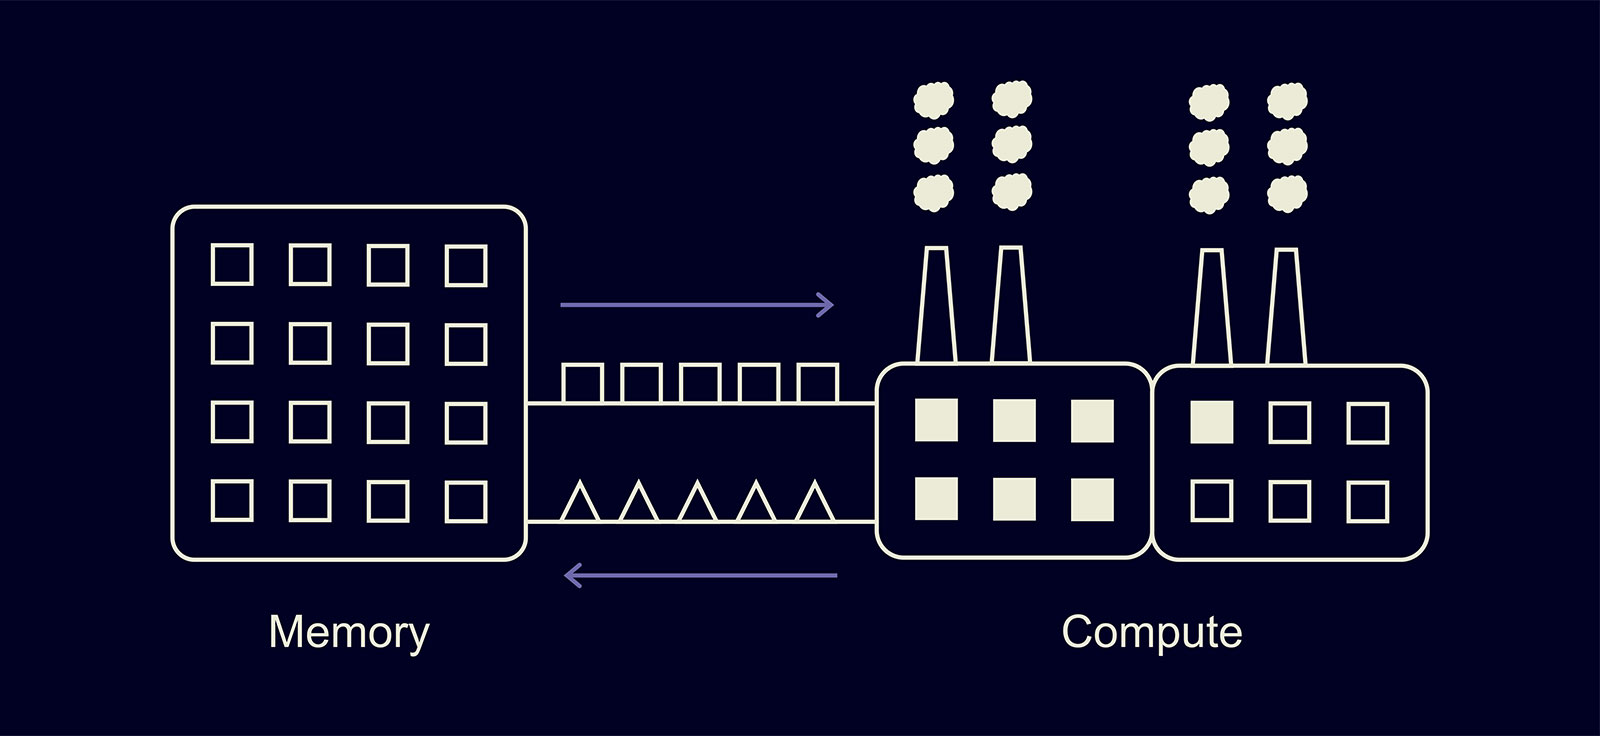

Основные метрики производительности:
- RPS (Requests per Second) - число обарботанных HTTPS-запросов в секунду.
- Latency - время (в мс), необходимое для обработки 1 запроса.

Модельный пример:
- $r = 2000\:rps$ - полная нагрузка
- $latency < 3\:s/req.$ - предельное допустимое latency
- $c = 20\%$ - cache hit
- $r_{peak} = r\cdot (1 - c) = 1800\:rps$ - пиковая нагрузка, $r_{avg} = 1600\:rps$ - средняя нагрузка
- $r_{GPU} = 6\:rps$ - нагрузка для 1 GPU
- $n_{GPU} \geq r_{peak} / r_{GPU} = 300 > 200 = n_{GPU}^{real}$ - нехватка мощностей для обеспечения пиковой нагрузки

Чаще всего рассматривают tradeoff между качеством модели и производительностью на инференсе. Для этого полезен анализ Pareto-кривых и поиск Pareto-оптимальных точек. Однако остается насущным вопрос, как добавлять в траекторию новые точки, являющиеся потенциально более оптимальными.

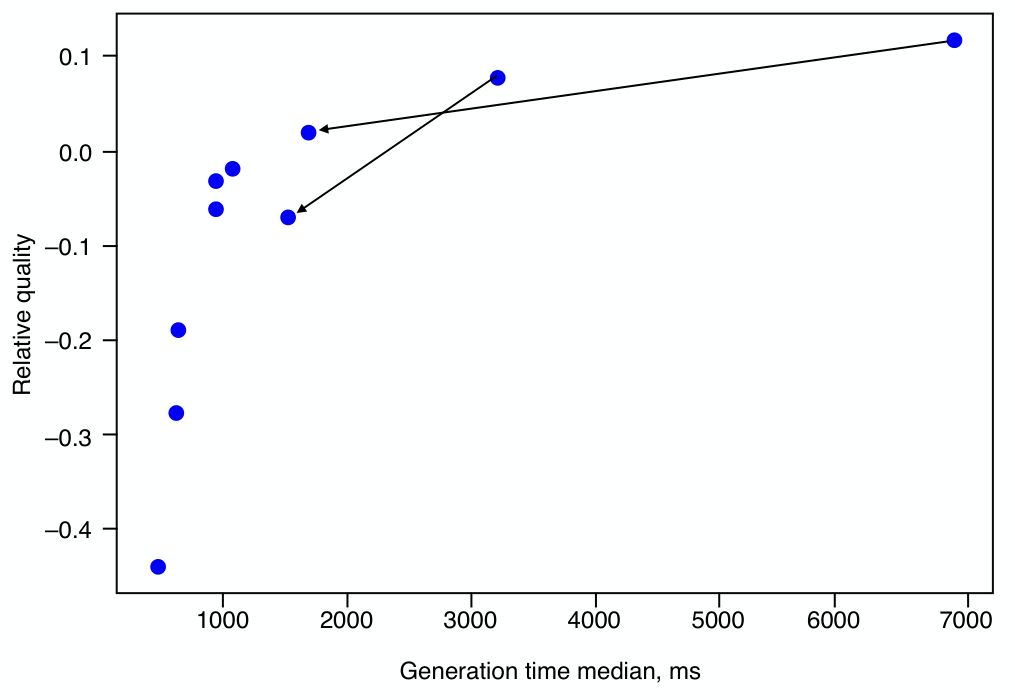

Классификация (по токенам/всего текста/задачи аннотации текста итд.):
- Охватывается огромный контекст
- Квадратная маска внимания
- 1 forward
- General Matrix-Matrix Multiplication (GEMM)
- Compute bound

Генерация (авто-регрессионная)
- Треугольная маска
- 1 forward/token
- General Matrix-Vector Multiplication (GEMV)
- Загрузука весов на каждом шаге
- Memory bound

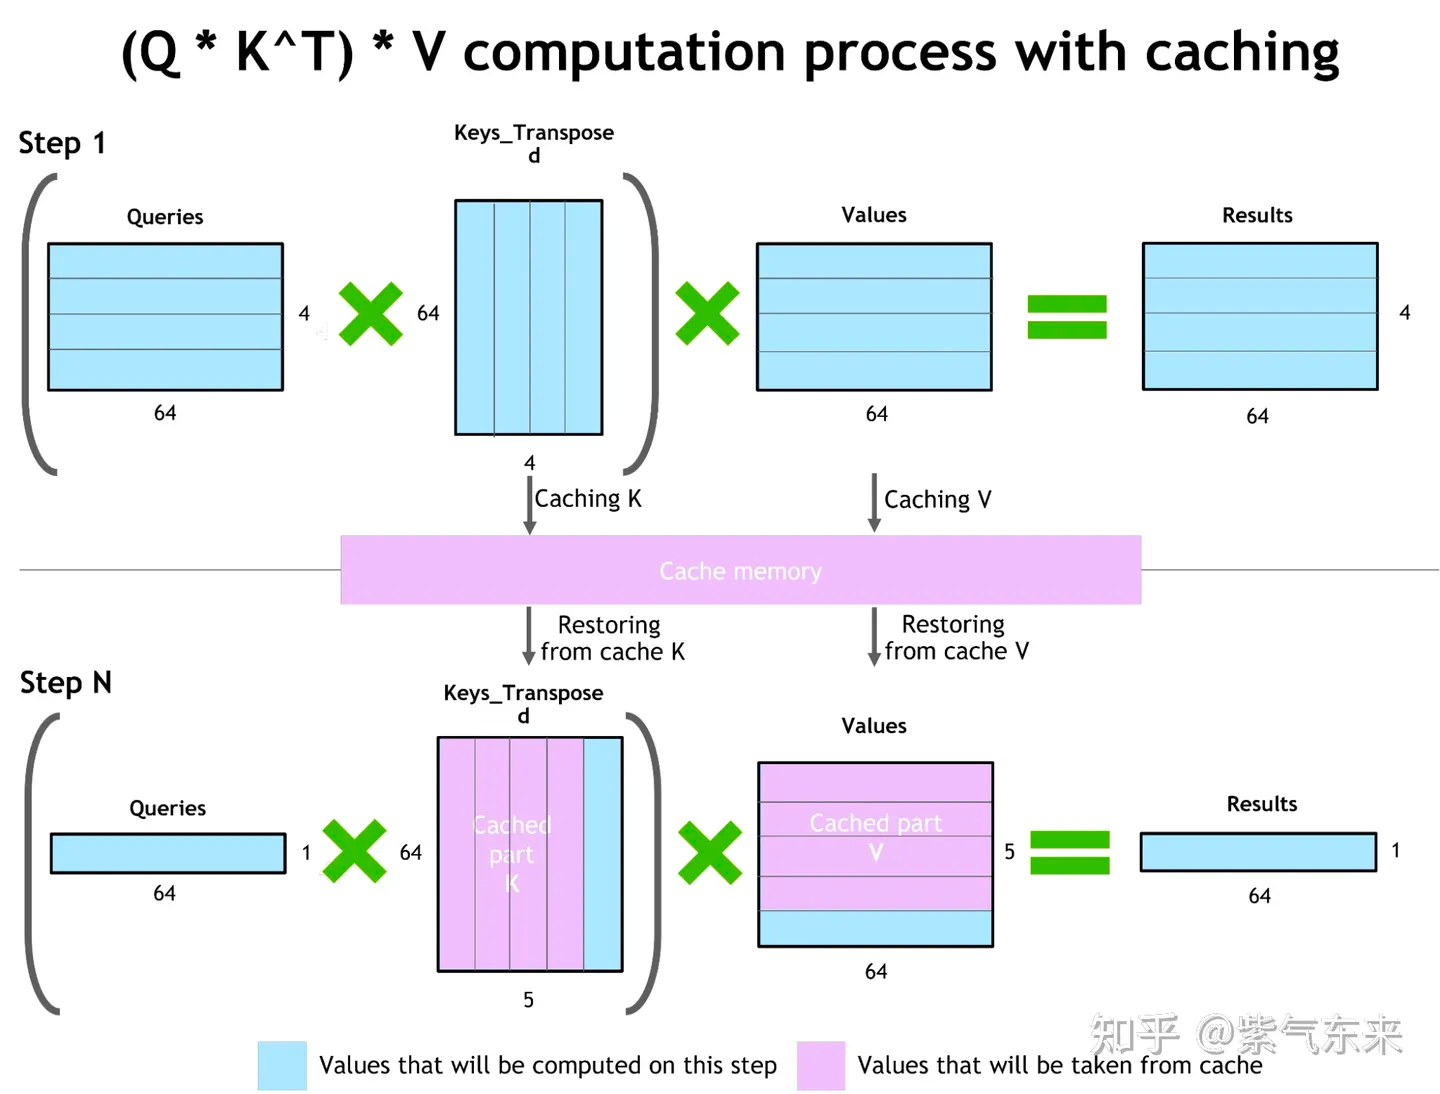

Как достигнуть Compute-bound:
- Большой batch-size (GEMV $\times BS →$ GEMM)
- Малый размер модели (меньше загрузки весов)
- Encoder-Decoder модели (только 30% весов приходится на decoder)
- Архитектурные методики
  - Multi-head (multi-query, grouped-query) attention (ускоренное чтение из памяти по головам)
  - Mixture of experts (увеличение объема вычислений при сохранении объема модели в FFN слоях)

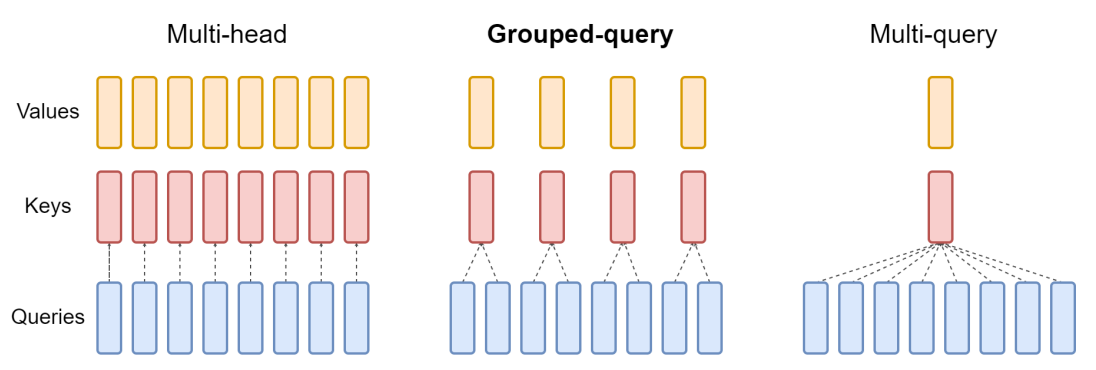

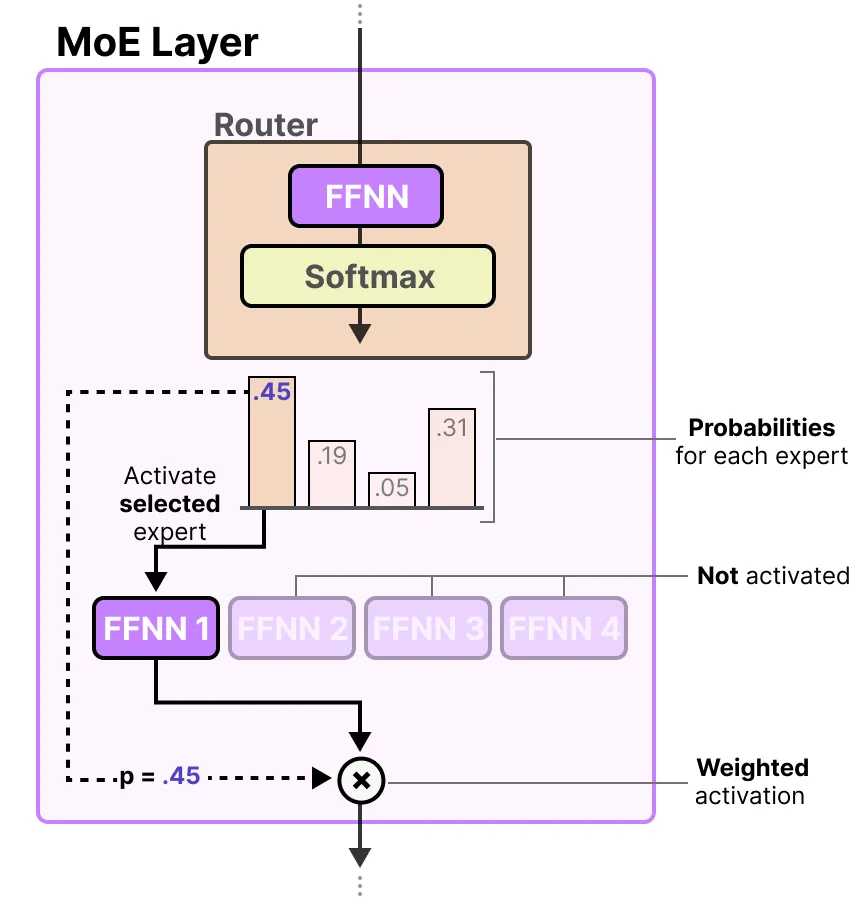

# Батчирование

Итак, пусть в модель одновременно пришло несколько запросов. Веса модели у них общие, а контекст и KV-cache — свои. Значит, можно выполнять часть вычислений вместе. При этом при выборе размера батча хотим приблизиться к compute bound, сохранив приемлемое latency.

## От GEMV к GEMM

[NVIDIA Matrix Multiplication Background](https://docs.nvidia.com/deeplearning/performance/dl-performance-matrix-multiplication/index.html)

В упрощенном виде GEMV: $$y = Wx$$
GEMM: $$Y = W[x_1,...,x_B]$$
где $x, x_1, ..., x_B$ - вектора-запросы.

Приближенная арифметическая интенсивность вычислений:
$$AI = (2BP) / (Ps) = 2B/s$$
где $P$ - число весов, $s$ - размер веса в байтах (float64, float16, bf16, int4). Таким образом, казалось бы, удается увеличить интенсивность вычислений при сохранении той же модели.



## Ограничения размера батча

[DistServe](https://arxiv.org/abs/2401.09670)
1. Кратное увеличение KV-кешей под каждый запрос.
2. Необходимость поддержания приемлемого latency.
3. Общее время работы на 1 батче преимущественно зависит от длины входных и генерируемых контекстов.
4. Пропускная способность памяти и производительность вычислений.


Также требуются новые метрики производительности:
- **TTFT** (Time To First Token) — время от запроса до первого токена, включая очередь.
- **ITL / TBT** — интервалы между следующими токенами.
- **Throughput** — запросы/с или токены/с; важно указать, какие токены считаем.
- **Goodput** — скорость обслуживания запросов, уложившихся в требования к задержкам (SLO).

Опять же приходим к Парето-оптимизации: увеличивая Throughput, мы увеличиваем и TTFT.

## Static and dynamic batching

[NVIDIA Triton — Dynamic Batcher](https://docs.nvidia.com/deeplearning/triton-inference-server/user-guide/docs/user_guide/batcher.html)

Рассмотренная ранее наивная техника батчирования обладает потеницально высокой задержкой и сильно зависит от длины самого длинного запроса в батче (остальные дополняются паддингом). Последнее приводит к отдалению от compute bound и снижению интенсивности вычислений. Кроме того, еще большая задержка происходит из-за ожидания заполнения всего батча.

Один из способов улучшить данный подход - динамическое батчирование. По истечении допустимого времени даже неплоный батч отправляется на обработку. Однако, это позволяет решить только последнюю критическую проблему статического батчирования.

## Continuous batching

Меняем единицу планирования: не весь ответ, а одна итерация генерации.

После каждой итерации:
1. Убираем завершённые запросы.
2. Добавляем новые, если есть ресурсы.
3. Собираем следующий батч.

Эта идея — основа iteration-level scheduling в Orca:
[Orca](https://www.usenix.org/system/files/osdi22-yu.pdf)

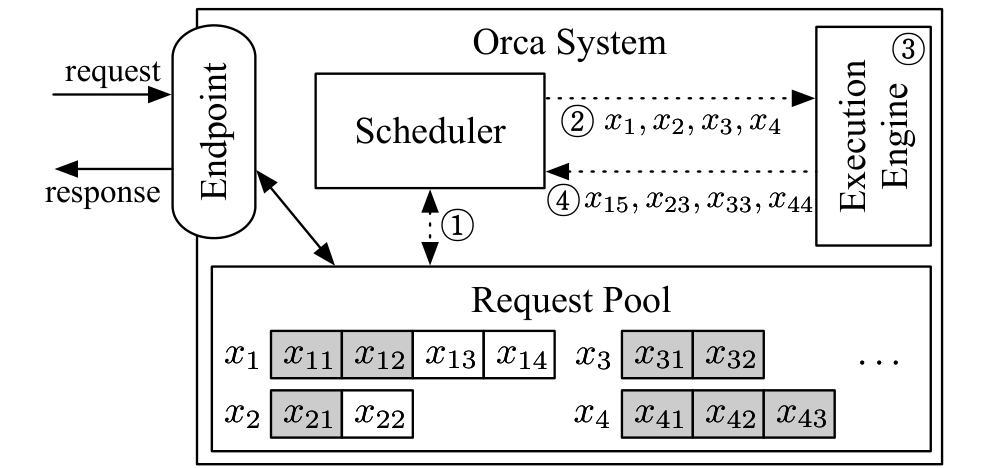

### Модельный пример

Пусть доступны 3 места в батче. В очереди запросы с числом decode-шагов:

$$A:2,\quad B:5,\quad C:3,\quad D:4,\quad E:2.$$

Сравним фиксированные батчи и пополнение после каждого шага.

Static batching: 9 шагов; 16/27 полезных слотов
Continuous batching: 6 шагов; 16/18 полезных слотов


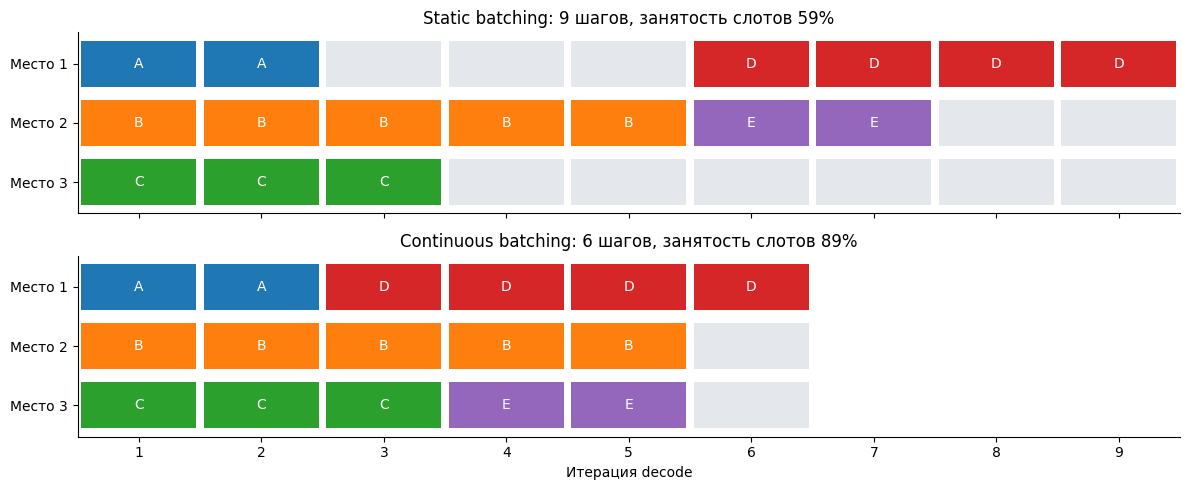

In [ ]:
from collections import deque
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

requests = [("A", 2), ("B", 5), ("C", 3), ("D", 4), ("E", 2)]
capacity = 3


def make_schedule(requests, capacity, continuous):
    assert capacity > 0 and all(length > 0 for _, length in requests)
    queue = deque(requests)
    slots = [None] * capacity
    remaining = {}
    history = []
    while queue or any(name is not None for name in slots):
        if continuous or all(name is None for name in slots):
            for slot in range(capacity):
                if slots[slot] is None and queue:
                    name, length = queue.popleft()
                    slots[slot] = name
                    remaining[name] = length
        history.append(slots.copy())
        for slot, name in enumerate(slots):
            if name is not None:
                remaining[name] -= 1
                if remaining[name] == 0:
                    slots[slot] = None
    return history


schedules = {
    "Static batching": make_schedule(requests, capacity, False),
    "Continuous batching": make_schedule(requests, capacity, True),
}
colors = {name: plt.get_cmap("tab10")(i % 10) for i, (name, _) in enumerate(requests)}
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
max_steps = max(map(len, schedules.values()))
for ax, (title, history) in zip(axes, schedules.items()):
    for step, batch in enumerate(history):
        for slot, name in enumerate(batch):
            ax.barh(slot, .94, left=step + .03, height=.78,
                    color=colors[name] if name else "#e4e7eb")
            if name:
                ax.text(step + .5, slot, name, ha="center", va="center", color="white")
    useful = sum(name is not None for batch in history for name in batch)
    occupancy = useful / (capacity * len(history))
    ax.set(title=f"{title}: {len(history)} шагов, занятость слотов {occupancy:.0%}",
           yticks=range(capacity), yticklabels=[f"Место {i+1}" for i in range(capacity)])
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)
    print(f"{title}: {len(history)} шагов; {useful}/{capacity * len(history)} полезных слотов")
axes[-1].set(xticks=[i + .5 for i in range(max_steps)],
             xticklabels=range(1, max_steps + 1), xlabel="Итерация decode", xlim=(0, max_steps))
fig.tight_layout()
plt.show()

## Prefill

**Prefill** - первая стадия LLM инференса, заключающаяся в анализе входного контекста (промпта) и построении начального состояния KV-cache. При длинном размере prefill возникает высокая задержка до начала стадии декодирования, что все еще затрагивает Continuous batching.

Идея **chunked prefill**:
- Разбить prompt на части.
- На каждом шаге выполнять decode активных запросов и часть нового prefill.
- Ограничивать число токенов, которые попадают в одну итерацию.

Например, бюджет — 512 токенов. Если выполняем 32 decode-токена, под prefill остаётся до 480.

Размер чанка задаёт tradeoff: эффективность prefill, TTFT нового запроса и ITL уже работающих.

Источник: [Sarathi-Serve](https://arxiv.org/abs/2403.02310).

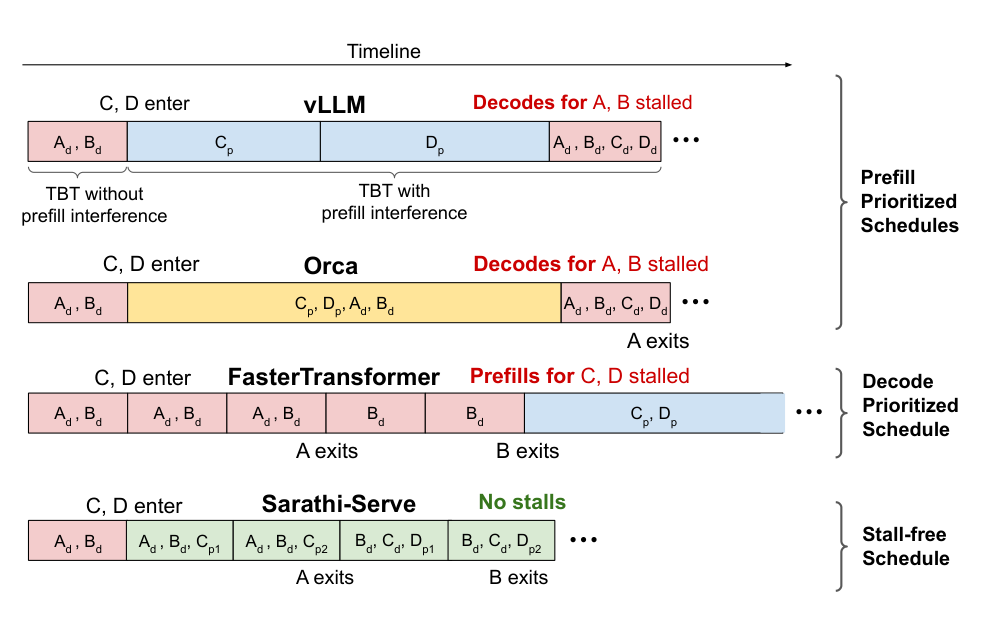

# Фреймворки для инференса

Тем не менее, батчирование все еще не решает две концептуальные проблемы:
1. Проблема нехватки памяти из-за кратного увеличения KV-кэшей.
2. Независимость длин и времени прихода запросов, которая сильно влияет на итоговую производительность и задержку.

Движок должен одновременно:
- Хранить очередь и состояние генерации каждого запроса.
- Решать, какие токены обрабатывать на следующем шаге.
- Выделять память под растущий KV-cache.
- Запускать вычисления на GPU и выдавать результат пользователю.
- Освобождать ресурсы после завершения или отмены запроса.

Удобно разбирать это на примере vLLM ([vLLM — Architecture Overview](https://docs.vllm.ai/en/latest/design/arch_overview/)):

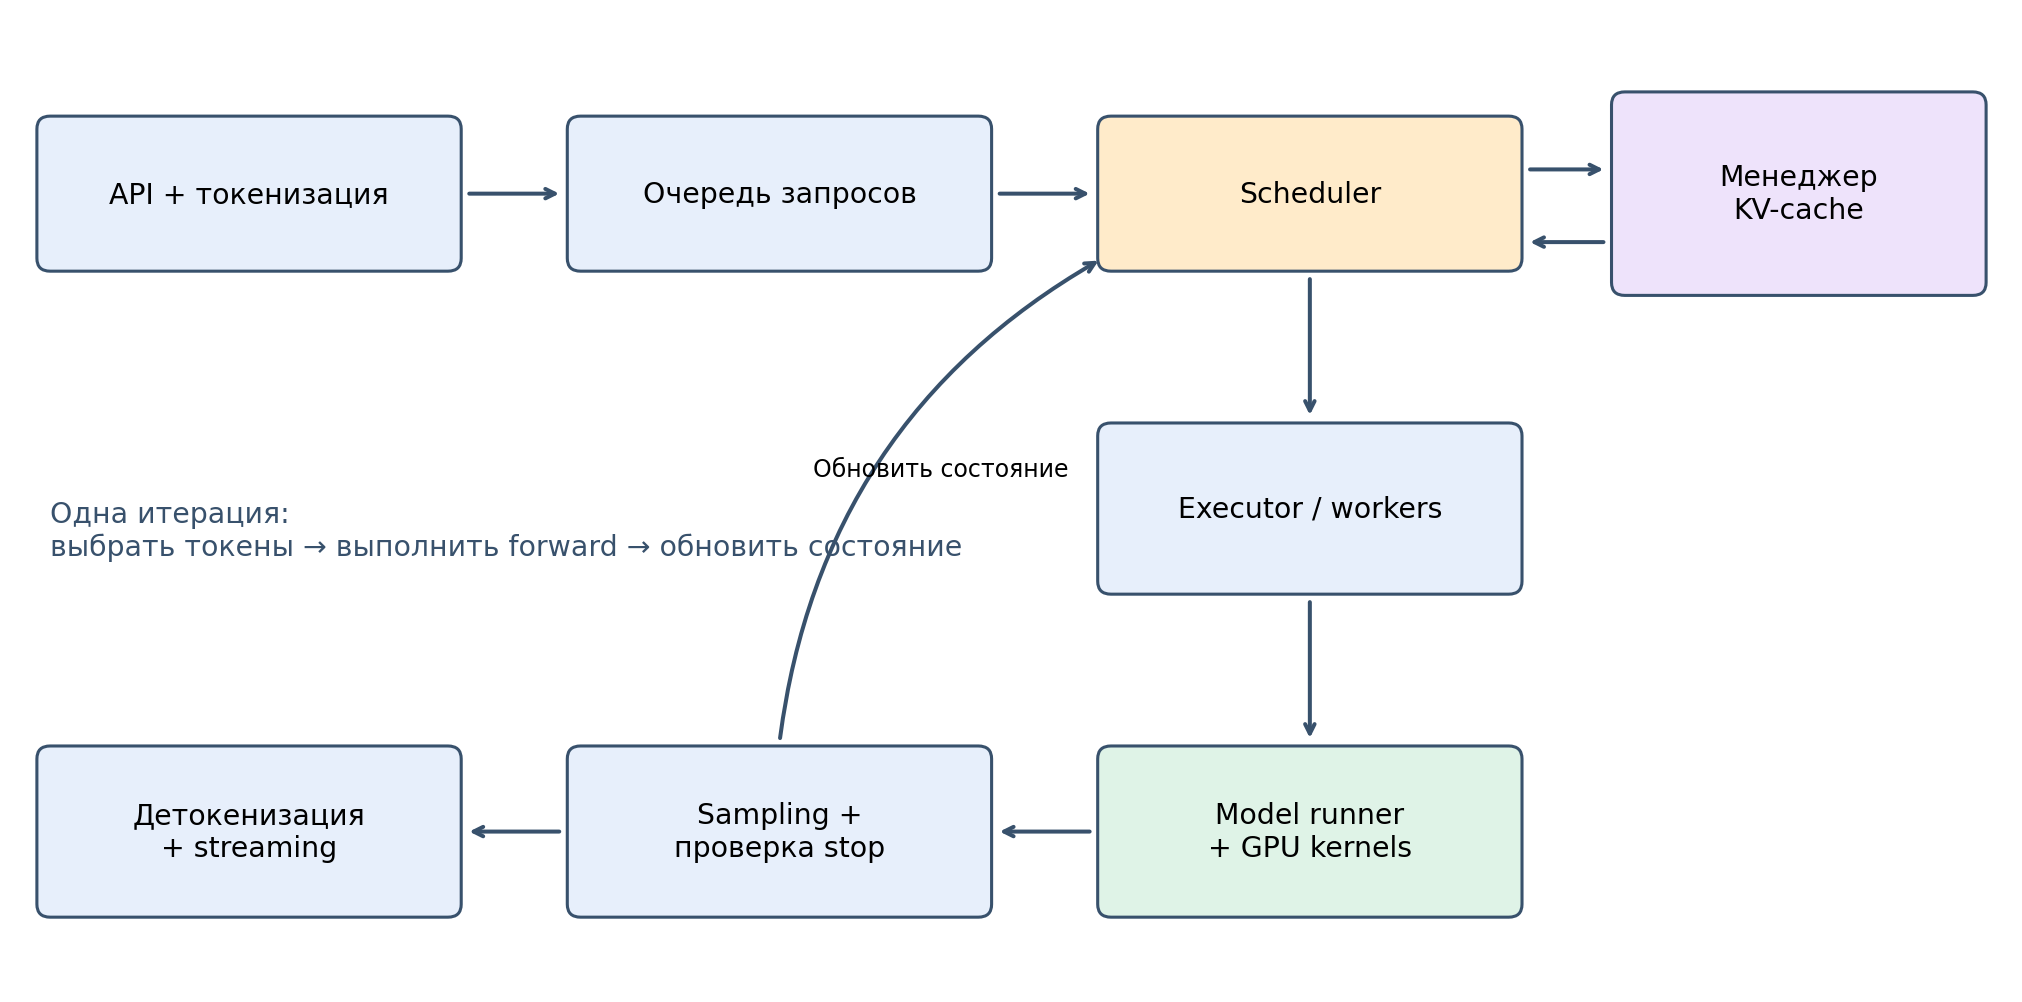

Основные компоненты системы:
- **Scheduler** выбирает запросы и число токенов для следующей итерации. Учитывает очередь, token budget и свободный KV-cache.

- **Executor / workers** организуют выполнение модели на одном или нескольких GPU.

- **Model runner** готовит входы, позиции и метаданные attention, запускает kernels.

- **Sampling** выбирает новые токены по логитам. Затем обновляем состояние и проверяем условия завершения.

В vLLM V1 API-процесс занимается входом и streaming, engine core — планированием и управлением KV, а GPU workers — исполнением модели.

Это объясняет, почему низкая загрузка GPU может быть связана и с CPU: токенизацией, подготовкой батча, обменом между процессами.

## KV-cache

Объём зависит от длины контекста и количества одновременно активных запросов:

$$M_{KV}\approx 2L H_{KV}d_{head}s_{KV}\sum_i T_i.$$

- $2$ — сохраняем и K, и V.

- $L$ — число слоёв.

- $H_{KV}$ — число KV-голов; при GQA оно меньше числа query-голов.

- $d_{head}$ — размер головы, $s_{KV}$ — байт на элемент.

- $T_i$ — число сохранённых токенов запроса $i$.

Кеш растёт по мере генерации. Поэтому допустимый batch-size определяется не только весами модели.

Оценка без шардирования, sharing, фрагментации и служебной памяти; для sliding-window и гибридных моделей она меняется.

In [ ]:
layers = 32
kv_heads = 8
head_dim = 128
bytes_per_element = 2
context_tokens = 4096
batch_sizes = [1, 8, 16, 32]

kv_bytes_per_token = 2 * layers * kv_heads * head_dim * bytes_per_element
print(f"KV на один токен одного запроса: {kv_bytes_per_token / 2**10:.0f} KiB")
print(f"Контекст: {context_tokens} токенов на запрос")
print("Батч | KV-cache, GiB")
for batch in batch_sizes:
    kv_bytes = batch * context_tokens * kv_bytes_per_token
    print(f"{batch:5d} | {kv_bytes / 2**30:12.2f}")
print("\nЭто только KV-cache: веса, активации и служебные буферы не учтены.")

KV на один токен одного запроса: 128 KiB
Контекст: 4096 токенов на запрос
Батч | KV-cache, GiB
    1 |         0.50
    8 |         4.00
   16 |         8.00
   32 |        16.00

Это только KV-cache: веса, активации и служебные буферы не учтены.


## PagedAttention

Если заранее выделять каждому запросу большой непрерывный буфер, часть памяти будет ждать будущие токены или так и останется неиспользованной.

Решение:
- Разбить KV-cache на блоки фиксированного размера.
- Хранить таблицу соответствия логических и физических блоков.
- Выделять новые блоки по мере роста последовательности.
- Читать K/V через таблицу блоков, даже если они лежат не подряд.

Логический контекст остаётся последовательным, физическое размещение может быть разным. Меньше потерь памяти — больше места для активных запросов.

Источник: [PagedAttention](https://arxiv.org/abs/2309.06180).

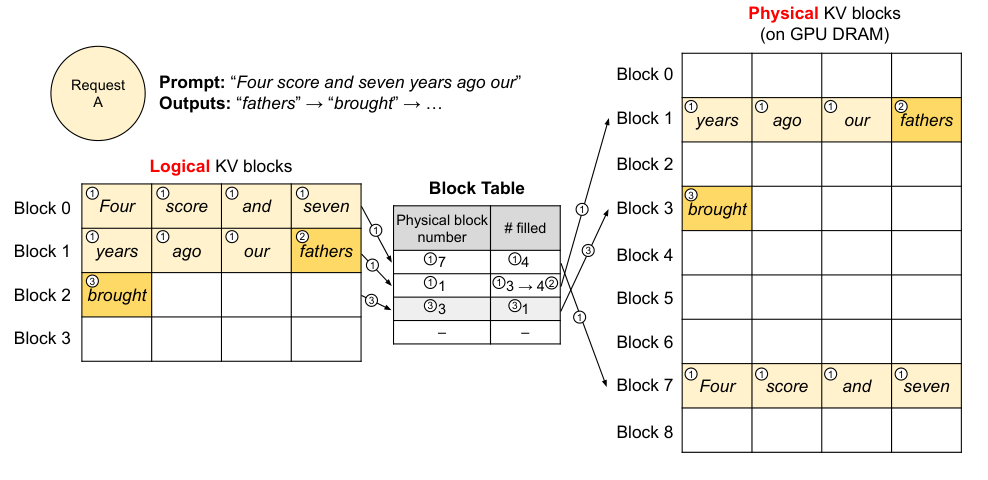

## Prefix caching

У нескольких запросов могут совпадать system prompt, начало истории диалога или длинный документ.

**Prefix caching** позволяет повторно использовать уже вычисленный KV для совпадающего начала:

- Сокращает работу prefill.

- Позволяет разделять состояние общего префикса.

- Не заменяет генерацию нового ответа кешированным текстом.

В **SGLang** для этого используется RadixAttention: префиксы представлены radix tree, а не независимыми буферами каждого запроса.

Важно совпадение вычислений: одна модель, те же токены, позиции и влияющие на результат настройки. Совпадающее слово в разных контекстах не означает одинаковый KV.

Источник: [SGLang, NeurIPS 2024](https://arxiv.org/abs/2312.07104).

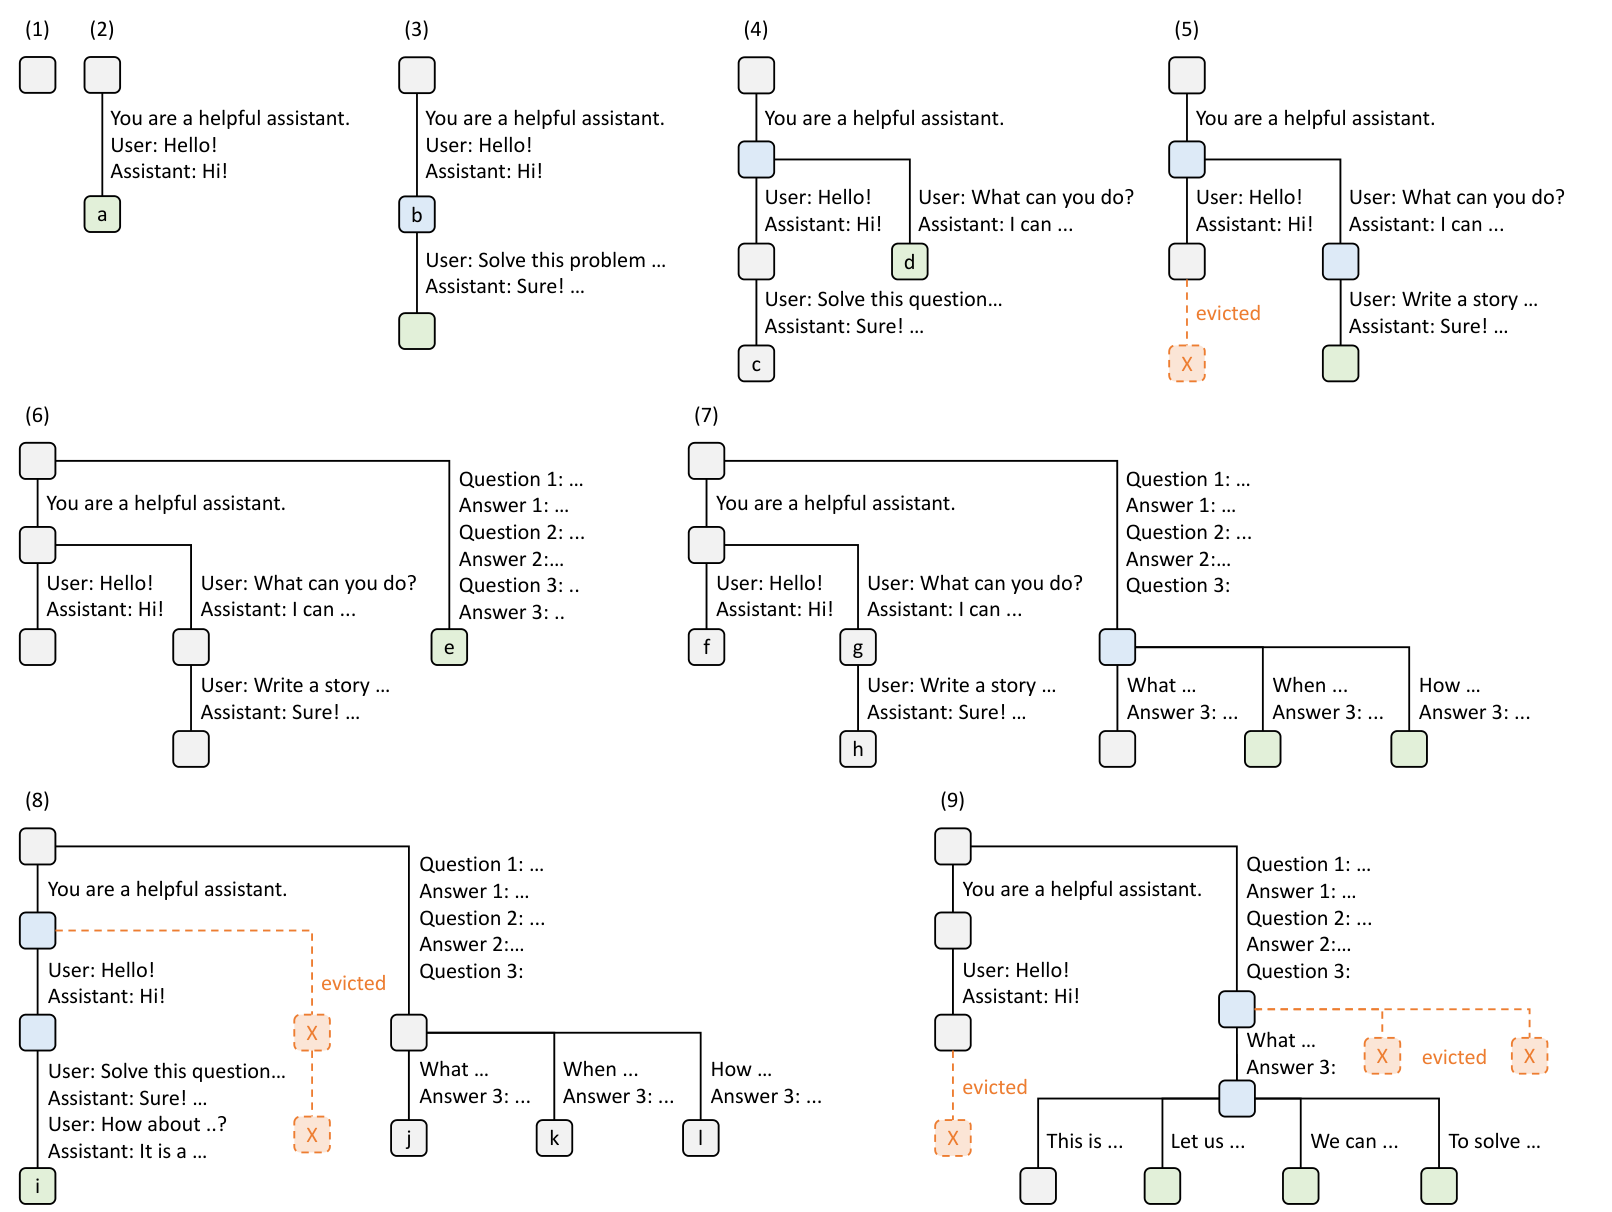

## CUDA и параллелизм

Помимо всего вышеописанного существуют оптимизации на уровне отдельных CUDA kernels:

- **FlashAttention:** блочное вычисление attention с меньшим обменом HBM ↔ SRAM, без хранения полной матрицы attention в HBM. Само число операций full attention остаётся квадратичным по длине последовательности.

- **Fusion:** объединение операций, чтобы реже записывать и читать промежуточные результаты.

- **CUDA Graphs:** повторный запуск подготовленного графа для поддерживаемых форм входа, чтобы снизить накладные расходы запуска.

PagedAttention отвечает за работу с KV, размещённым по блокам; FlashAttention — за эффективное вычисление attention. Эти идеи могут сочетаться.

Источники: [FlashAttention](https://arxiv.org/abs/2205.14135), [PyTorch — CUDA Graphs](https://pytorch.org/blog/accelerating-pytorch-with-cuda-graphs/).

Повышение производительности в современных условиях при работе с моделями и контекстами неимоверно больших размеров невозможно без различных видов параллелизма:

- **Data parallelism:** несколько копий модели обслуживают разные запросы.

- **Tensor parallelism:** части операций и весов распределены между GPU; внутри forward нужен обмен результатами.

- **Pipeline parallelism:** группы слоёв находятся на разных GPU.

- **Expert parallelism:** эксперты MoE распределены между GPU; токены нужно маршрутизировать к ним.

Больше GPU не всегда означает пропорциональное ускорение: появляются коммуникации, дисбаланс и простои.

Источники: [Orca](https://www.usenix.org/system/files/osdi22-yu.pdf), [vLLM — Parallelism and Scaling](https://docs.vllm.ai/en/latest/serving/parallelism_scaling/), [DistServe](https://arxiv.org/abs/2401.09670).

## Disaggregated inference

[DistServe](https://arxiv.org/abs/2401.09670)

Предлагается обрабатывать стадии prefill и декодирования по-разному ввиду их особенностей:

- **Prefill** обрабатывает много входных токенов сразу. Он обычно хорошо использует матричные операции и определяет **TTFT** — время до первого токена.
- **Decode** генерирует по одному токену для каждого активного запроса. Он чаще упирается в чтение весов и KV-cache и определяет **ITL/TBT** — паузу между токенами.

Если смешать режимы, длинный prefill может занять вычислительный бюджет и увеличить паузу между токенами у уже идущих ответов. Увеличение batch size помогает загрузить decode, но само по себе этот конфликт не устраняет.


**Disaggregated inference** разделяет эти стадии на независимые группы воркеров:

1. `prefill-workers` обрабатывают prompt и строят KV-cache.

2. Контроллер передаёт KV-cache и метаданные в `decode-workers`.

3. `decode-workers` продолжают авторегрессию и отдают токены пользователю по мере готовности.

4. Пулы масштабируются и настраиваются отдельно под свои SLO и тип нагрузки.

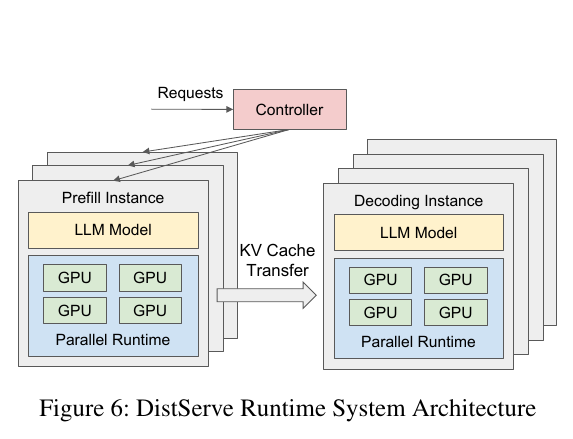

Разделение даёт несколько практических эффектов:

- можно независимо добавлять prefill- или decode-GPU, когда входы и ответы имеют разную нагрузку;

- можно выбрать разные степени tensor/pipeline parallelism для двух стадий;

- TTFT и ITL становятся менее зависимыми друг от друга, поэтому проще выдерживать разные SLO.

Цена — передача KV-cache между пулами. Она добавляет сетевой трафик, сериализацию и синхронизацию; KV должен быть совместим по модели, dtype, позициям и attention-конфигурации. При низкой нагрузке отдельные пулы могут простаивать, поэтому disaggregation оправдан только после измерения длины prompt/output, bandwidth и целевых SLO.